## LangGraph migration for collect_energy

In [47]:
from __future__ import annotations

import argparse
import json
import time
from pathlib import Path
from typing import Any, Dict, List, Tuple

import numpy as np

In [48]:
from lib.datagen.dynamics import Replica, run_forward_dynamics
from lib.datagen.graph import make_lattice_J, sample_J_num_edges_symmetric
from lib.datagen.utils import make_gemini_pi, make_mock_pi, make_openai_pi, \
                    make_together_pi, make_aihubmix_pi, make_openrouter_pi

In [49]:
from IPython.display import Image, display
import operator
from typing import Annotated, List, Literal, TypedDict
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt

In [50]:
class State(TypedDict):
    """State of the workflow."""
    replicas: Annotated[List[str], operator.add]
    step: int
    num_steps: int

In [51]:
def init_node(state: State) -> State:
    """Initialize the workflow state."""
    return {
        'replicas': [],
        'step': 0,
        }

In [52]:
def message_node(state: State) -> dict:
    """Message exchange between agents."""
    step = state['step'] + 1

    return {
        'replicas': [f"message phase {step}"],
        'step': step,
    }

In [53]:
def spins_node(state: State) -> dict:
    """Spin update of the agents."""
    return {
        'replicas': [f"spin phase {state['step']}"],
    }

In [54]:
def save_node(state: State) -> dict:
    """Save the state of the workflow."""
    return {
        'replicas': [f"save phase {state['step']}"],
    }

In [55]:
def check_steps(state: State) -> Literal["message", END]:
    """Routing function to determine if we should continue or end the workflow."""
    if state['step'] < state['num_steps']:
        return "message"
    else:
        return END

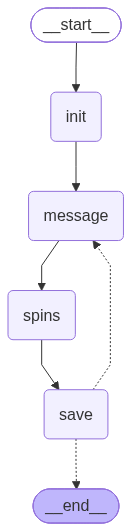

In [56]:
builder = StateGraph(State)

# Add nodes
builder.add_node('init', init_node)
builder.add_node('message', message_node)
builder.add_node('spins', spins_node)
builder.add_node('save', save_node)

# Add edges
builder.add_edge(START, 'init')
builder.add_edge('init', 'message')
builder.add_edge('message', 'spins')
builder.add_edge('spins', 'save')
builder.add_conditional_edges('save', check_steps, )

# Compile and display
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [57]:
graph.invoke({'num_steps': 3})

{'replicas': ['message phase 1',
  'spin phase 1',
  'save phase 1',
  'message phase 2',
  'spin phase 2',
  'save phase 2',
  'message phase 3',
  'spin phase 3',
  'save phase 3'],
 'step': 3,
 'num_steps': 3}